In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

In [2]:
data_dir = "C:\\Users\\rimor\\Downloads\\archive\\IMG_CLASSES"

In [3]:
#figuring the content of the main folder directory

os.listdir(data_dir)

['Atopic Dermatitis',
 'Basal Cell Carcinoma',
 'Benign Keratosis-like Lesions',
 'Eczema',
 'Melanocytic Nevi',
 'Melanoma',
 'Psoriasis pictures Lichen Planus and related diseases',
 'Seborrheic Keratoses and other Benign Tumors',
 'Tinea Ringworm Candidiasis and other Fungal Infections',
 'Warts Molluscum and other Viral Infections']

In [4]:
#figuring the images inside one of the folder inside data_dir

os.listdir(os.path.join(data_dir,'Eczema'))

['0_0.jpg',
 '0_1.jpg',
 '0_10.jpg',
 '0_11.jpg',
 '0_12.jpg',
 '0_13.jpg',
 '0_14.jpg',
 '0_15.jpg',
 '0_16.jpg',
 '0_17.jpg',
 '0_18.jpg',
 '0_19.jpg',
 '0_2.jpg',
 '0_20.jpg',
 '0_21.jpg',
 '0_22.jpg',
 '0_23.jpg',
 '0_24.jpg',
 '0_25.jpg',
 '0_26.jpg',
 '0_27.jpg',
 '0_28.jpg',
 '0_29.jpg',
 '0_3.jpg',
 '0_30.jpg',
 '0_31.jpg',
 '0_32.jpg',
 '0_33.jpg',
 '0_34.jpg',
 '0_35.jpg',
 '0_36.jpg',
 '0_37.jpg',
 '0_38.jpg',
 '0_39.jpg',
 '0_4.jpg',
 '0_40.jpg',
 '0_41.jpg',
 '0_42.jpg',
 '0_5.jpg',
 '0_6.jpg',
 '0_7.jpg',
 '0_8.jpg',
 '0_9.jpg',
 '1_0.jpg',
 '1_1.jpg',
 '1_10.jpg',
 '1_11.jpg',
 '1_12.jpg',
 '1_13.jpg',
 '1_14.jpg',
 '1_15.jpg',
 '1_16.jpg',
 '1_17.jpg',
 '1_18.jpg',
 '1_19.jpg',
 '1_2.jpg',
 '1_20.jpg',
 '1_21.jpg',
 '1_22.jpg',
 '1_23.jpg',
 '1_24.jpg',
 '1_25.jpg',
 '1_26.jpg',
 '1_3.jpg',
 '1_4.jpg',
 '1_5.jpg',
 '1_6.jpg',
 '1_7.jpg',
 '1_8.jpg',
 '1_9.jpg',
 '2_0.jpg',
 '2_1.jpg',
 '2_10.jpg',
 '2_11.jpg',
 '2_12.jpg',
 '2_13.jpg',
 '2_14.jpg',
 '2_15.jpg',
 '2_16.j

In [5]:
img=cv2.imread(os.path.join(data_dir,'Eczema','v-stasis-dermatitis-97.jpg'))
img.shape

(480, 720, 3)

In [6]:
"""
import cv2 #opencv
from PIL import Image

for image_class in os.listdir(data_dir):
  for image in os.listdir(os.path.join(data_dir,image_class)):
    image_path = os.path.join(data_dir,image_class,image)
    try:
      img = cv2.imread(image_path)
      with Image.open(image_path) as img_1:
        tip = img_1.format.lower()
      if tip not in ['jpeg','jpg','png','bmp']:
        print('Image not in the right format')
        os.remove(image_path)
    except Exception as e:
      print(f"Issue with image {image_path}")
      """

'\nimport cv2 #opencv\nfrom PIL import Image\n\nfor image_class in os.listdir(data_dir):\n  for image in os.listdir(os.path.join(data_dir,image_class)):\n    image_path = os.path.join(data_dir,image_class,image)\n    try:\n      img = cv2.imread(image_path)\n      with Image.open(image_path) as img_1:\n        tip = img_1.format.lower()\n      if tip not in [\'jpeg\',\'jpg\',\'png\',\'bmp\']:\n        print(\'Image not in the right format\')\n        os.remove(image_path)\n    except Exception as e:\n      print(f"Issue with image {image_path}")\n      '

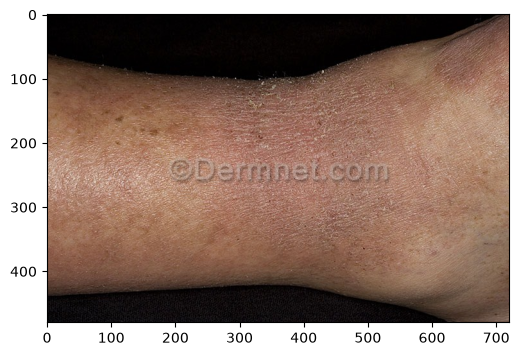

In [7]:
#just trying out one img and showing its using matplotlib

plt.figure(figsize=(6,4))
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))

# **Creating the Data Frame**

In [8]:
#creating the pipeline for data collection
data = tf.keras.utils.image_dataset_from_directory(data_dir, image_size=(256, 256), batch_size=16, shuffle=False)

Found 27153 files belonging to 10 classes.


In [9]:
# Get number of classes
num_classes = len(data.class_names)

print("Number of classes:", num_classes)
print("Classes:", data.class_names)

Number of classes: 10
Classes: ['Atopic Dermatitis', 'Basal Cell Carcinoma', 'Benign Keratosis-like Lesions', 'Eczema', 'Melanocytic Nevi', 'Melanoma', 'Psoriasis pictures Lichen Planus and related diseases', 'Seborrheic Keratoses and other Benign Tumors', 'Tinea Ringworm Candidiasis and other Fungal Infections', 'Warts Molluscum and other Viral Infections']


# **Data Preprocessing**

In [10]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 16

# Get total number of images BEFORE modifying the dataset
num_images = len(data.file_paths)

print("Total images:", num_images)

# Unbatch dataset
data = data.unbatch()

# Shuffle complete dataset
data = data.shuffle(
    buffer_size=num_images,
    seed=42,
    reshuffle_each_iteration=False
)

# Normalize images
data = data.map(
    lambda x, y: (x / 255.0, y),
    num_parallel_calls=AUTOTUNE
)

# Calculate split sizes based on images
train_size = int(num_images * 0.7)
val_size = int(num_images * 0.2)
test_size = num_images - train_size - val_size

# Split dataset by individual images
train = data.take(train_size)

val = data.skip(train_size).take(val_size)

test = data.skip(train_size + val_size)

# Shuffle training images between epochs
train = train.shuffle(
    buffer_size=min(train_size, 1000),
    reshuffle_each_iteration=True
)

# Batch datasets
train = train.batch(BATCH_SIZE)
val = val.batch(BATCH_SIZE)
test = test.batch(BATCH_SIZE)

# Prefetch datasets
train = train.prefetch(AUTOTUNE)
val = val.prefetch(AUTOTUNE)
test = test.prefetch(AUTOTUNE)

# Display dataset information
print("\nDataset Distribution")
print("---------------------")

print("Total images:", num_images)

print("Training images:", train_size)
print("Validation images:", val_size)
print("Testing images:", test_size)

print("\nDataset Batches")
print("---------------------")

print("Training batches:", tf.data.experimental.cardinality(train).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test).numpy())

Total images: 27153

Dataset Distribution
---------------------
Total images: 27153
Training images: 19007
Validation images: 5430
Testing images: 2716

Dataset Batches
---------------------
Training batches: -2
Validation batches: -2
Testing batches: -2


# **Model Creation**

In [11]:
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras import Sequential
from tensorflow.keras.optimizers import Adam



def build_cnn_model(hp):

    model = Sequential()

    # Input layer
    model.add(tf.keras.Input(shape=(256, 256, 3)))

    # Tune number of convolutional blocks
    conv_blocks = hp.Int('conv_blocks', min_value=2, max_value=4, step=1)

    # Convolutional layers
    for i in range(conv_blocks):

        filters = hp.Choice( f'filters_{i}',values=[16, 32, 64, 128])

        kernel_size = hp.Choice(f'kernel_{i}',values=[3, 5])

        model.add(Conv2D(filters=filters,kernel_size=kernel_size,activation='relu',padding='same'))

        # Tune Batch Normalization
        if hp.Boolean(f'batch_norm_{i}'):
            model.add(BatchNormalization())

        model.add(MaxPooling2D(pool_size=(2, 2)))


    # Feature extraction
    model.add(GlobalAveragePooling2D())


    # Tune dropout
    dropout_rate = hp.Choice('dropout', values=[0.2, 0.3, 0.4, 0.5])

    model.add(Dropout(dropout_rate))


    # Tune Dense neurons
    dense_units = hp.Choice('dense_units',values=[64, 128, 256])

    model.add(Dense(dense_units,activation='relu'))

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))



    # Tune learning rate
    learning_rate = hp.Choice('learning_rate',values=[0.001, 0.0005, 0.0001])


    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [12]:
#tunig the model using keras tuner
import keras_tuner as kt

tuner = kt.RandomSearch(
    hypermodel=build_cnn_model,
    objective='val_accuracy',
    max_trials=20,
    executions_per_trial=1,
    directory='CNN_Tuning',
    project_name='Skin_Disease_CNN',
    overwrite=True
)

# **Model Training**

In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

tuner.search(
    train,
    validation_data=val,
    epochs=25,
    callbacks=[
        early_stop,
        reduce_lr
    ],
    verbose=1
)

Trial 2 Complete [05h 28m 05s]
val_accuracy: 0.5732964873313904

Best val_accuracy So Far: 0.5987108945846558
Total elapsed time: 08h 14m 59s

Search: Running Trial #3

Value             |Best Value So Far |Hyperparameter
3                 |4                 |conv_blocks
32                |16                |filters_0
3                 |3                 |kernel_0
True              |True              |batch_norm_0
64                |32                |filters_1
5                 |3                 |kernel_1
True              |False             |batch_norm_1
0.4               |0.2               |dropout
128               |64                |dense_units
0.001             |0.0005            |learning_rate
16                |16                |filters_2
3                 |3                 |kernel_2
True              |False             |batch_norm_2
128               |16                |filters_3
3                 |3                 |kernel_3
False             |False             |batch_nor

KeyboardInterrupt: 

In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("BEST HYPERPARAMETERS")
for key, value in best_hp.values.items():
    print(f"{key}: {value}")

In [ ]:
#getting the best model with the best hyperparameters
best_model = tuner.get_best_models(num_models=1)[0]

In [ ]:
best_model.summary()

In [ ]:
final_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

final_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_best = best_model.fit(train, validation_data=val, epochs=50, callbacks=[final_early_stop], verbose=1)

In [ ]:
from sklearn.metrics import classification_report

y_true = np.concatenate([labels.numpy() for images, labels in test])
y_pred = np.argmax(best_model.predict(test), axis=1)

class_report = classification_report(y_true, y_pred, target_names=data.class_names)
print(class_report)



from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)

plt.title("CNN Confusion Matrix")
plt.show()

In [ ]:
best_model.save('best_model.h5')